# 07 · Production Hybrid CICIDS2017 NIDS

Run this notebook top-to-bottom. It implements a leakage-safe CICIDS2017 NIDS with:

1. Drive persistence, raw audit, socket-column removal, train-only RF + MI feature selection, and cached arrays.
2. Engine A: Monday-benign FT-Transformer + TCN autoencoder for zero-day detection.
3. Engine B: unsupervised clustering of Engine A's Thursday/Friday anomalous traffic.
4. Engine C: isolated Tuesday-Friday specialist FT-Transformer + TCN classifiers with StratifiedShuffleSplit 70/30.

Existing notebooks are left intact. This notebook writes under `/content/drive/MyDrive/NIDS_CICIDS2017_Project/production_hybrid_nids/`.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
ROOT = Path('/content/drive/MyDrive/NIDS_CICIDS2017_Project')
RAW, EXTRACT = ROOT/'raw', ROOT/'extracted_generated_flows'
BASE = ROOT/'production_hybrid_nids'
CACHE, FEAT, MODELS, REP, CLUST = [BASE/p for p in ['cache','features','models','reports','clusters']]
for d in [RAW, EXTRACT, BASE, CACHE, FEAT, MODELS, REP, CLUST]:
    d.mkdir(parents=True, exist_ok=True)

SEED = 42
SMOKE_TEST = False

import json, re, zipfile, joblib, gc
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.cluster import MiniBatchKMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import average_precision_score, classification_report, confusion_matrix, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.utils.class_weight import compute_class_weight

pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 80)
keras.utils.set_random_seed(SEED)
print('TensorFlow:', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))

Mounted at /content/drive
TensorFlow: 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1 · Audit, Cleaning, and Zero-Leakage Feature Selection

Socket identifiers are dropped before any model-facing feature list is created. Splits happen before medians, scaling, RF/MI ranking, clustering, or modeling.

In [2]:
DAYS = ['Monday','Tuesday','Wednesday','Thursday','Friday']
EXPECTED_DATE = {'Monday':'2017-07-03','Tuesday':'2017-07-04','Wednesday':'2017-07-05','Thursday':'2017-07-06','Friday':'2017-07-07'}
SOCKET_META = ['Flow ID','Source IP','Src IP','Source Port','Src Port','Destination IP','Dst IP','Destination Port','Dst Port','Protocol','Timestamp','Label']

def clean_label(s):
    return s.astype(str).str.strip().str.replace(r'[^\x20-\x7E]+','-',regex=True)

def parse_ts(s):
    s = s.astype(str).str.strip()
    t = pd.to_datetime(s, format='%d/%m/%Y %H:%M', errors='coerce')
    miss = t.isna()
    if miss.any():
        t.loc[miss] = pd.to_datetime(s.loc[miss], dayfirst=True, errors='coerce', format='mixed')
    return t.where(t.dt.hour >= 8, t + pd.Timedelta(hours=12))

def day_from_name(p):
    return next(d for d in DAYS if d.lower() in p.name.lower())

def locate_csvs():
    csvs = sorted(EXTRACT.rglob('*.csv'))
    if len(csvs) != 8:
        zips = list(ROOT.rglob('GeneratedLabelledFlows*.zip'))
        assert zips, f'Put GeneratedLabelledFlows.zip under {RAW} or {ROOT}'
        with zipfile.ZipFile(zips[0]) as z:
            z.extractall(EXTRACT)
        csvs = sorted(EXTRACT.rglob('*.csv'))
    assert len(csvs) == 8, f'Expected 8 CSVs, found {len(csvs)}'
    return csvs

def build_clean_cache(force=False):
    if not force and all((CACHE/f'{d}.parquet').exists() for d in DAYS) and (FEAT/'raw_feature_candidates.json').exists():
        print('Clean cache already exists.')
        return
    audit, canonical = [], None
    for p in locate_csvs():
        day = day_from_name(p)
        df = pd.read_csv(p, low_memory=False, encoding_errors='replace')
        df.columns = [re.sub(r'\s+', ' ', str(c).strip()) for c in df.columns]
        n_raw = len(df)
        df = df.drop(columns=[c for c in df.columns if c == 'Fwd Header Length.1']).dropna(subset=['Label']).reset_index(drop=True)
        feats = [c for c in df.columns if c not in SOCKET_META]
        canonical = feats if canonical is None else canonical
        assert not (set(canonical) - set(feats)), f'Feature mismatch in {p.name}'
        X = df[canonical].apply(pd.to_numeric, errors='coerce')
        n_inf = int(np.isinf(X.to_numpy(dtype='float64')).sum())
        X = X.replace([np.inf, -np.inf], np.nan).astype('float32')
        out = X.copy()
        out['Timestamp'] = parse_ts(df['Timestamp'])
        out['Label'] = clean_label(df['Label'])
        out['day'] = day
        out['day_id'] = DAYS.index(day)
        assert out['Timestamp'].notna().all()
        out = out.sort_values('Timestamp').reset_index(drop=True)
        out.to_parquet(CACHE/f'{day}.parquet', index=False)
        dates = sorted(map(str, out['Timestamp'].dt.date.unique()))
        audit.append({'file':p.name,'day':day,'rows_raw':n_raw,'rows_clean':len(out),'blank_rows_dropped':n_raw-len(out),'labels':out.Label.nunique(),'inf_to_nan':n_inf,'nan_feature_cells':int(out[canonical].isna().sum().sum()),'dates':','.join(dates),'date_ok':dates==[EXPECTED_DATE[day]],'features_after_socket_drop':len(canonical)})
    pd.DataFrame(audit).sort_values('day').to_csv(REP/'cleaning_audit.csv', index=False)
    (FEAT/'raw_feature_candidates.json').write_text(json.dumps(canonical, indent=2))
    display(pd.DataFrame(audit).sort_values('day'))

build_clean_cache(False)
raw_features = json.loads((FEAT/'raw_feature_candidates.json').read_text())
def load_day(day): return pd.read_parquet(CACHE/f'{day}.parquet')
display(pd.concat([load_day(d).Label.value_counts().rename(d) for d in DAYS], axis=1).fillna(0).astype(int))
print('Behavior features after socket drop:', len(raw_features))
print('Excluded socket/meta fields:', SOCKET_META)

Clean cache already exists.


,Monday,Tuesday,Wednesday,Thursday,Friday
Label,,,,,
BENIGN,529918,432074,440031,168186,189067
FTP-Patator,0,7938,0,0,0
SSH-Patator,0,5897,0,0,0
DoS Hulk,0,0,231073,0,0
DoS GoldenEye,0,0,10293,0,0
DoS slowloris,0,0,5796,0,0
DoS Slowhttptest,0,0,5499,0,0
Heartbleed,0,0,11,0,0
Web Attack - Brute Force,0,0,0,1507,0


Behavior features after socket drop: 76
Excluded socket/meta fields: ['Flow ID', 'Source IP', 'Src IP', 'Source Port', 'Src Port', 'Destination IP', 'Dst IP', 'Destination Port', 'Dst Port', 'Protocol', 'Timestamp', 'Label']


In [3]:
TOP_K_FEATURES = 32
FS_TRAIN_DAYS = ['Monday','Tuesday','Wednesday']
FS_HELDOUT_DAYS = ['Thursday','Friday']

def slog(a):
    return (np.sign(a) * np.log1p(np.abs(a))).astype('float32')

ready = all((FEAT/p).exists() for p in ['selected_features.json','scaler.joblib','train_medians.joblib']) and all((CACHE/f'X_{d}.npy').exists() for d in DAYS)
if ready:
    selected = json.loads((FEAT/'selected_features.json').read_text())['features']
    scaler = joblib.load(FEAT/'scaler.joblib')
    print('Using persisted feature pipeline:', len(selected), 'features')
else:
    tr = pd.concat([load_day(d) for d in FS_TRAIN_DAYS], ignore_index=True)
    tr = tr[~tr.duplicated(subset=raw_features + ['Label'])].reset_index(drop=True)
    med = tr[raw_features].median()
    imp = tr[raw_features].fillna(med)
    constant = imp.nunique()[lambda s: s <= 1].index.tolist()
    rem = [c for c in raw_features if c not in constant]
    corr = imp[rem].sample(min(500_000, len(imp)), random_state=SEED).corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
    correlated = [c for c in upper.columns if (upper[c] > 0.95).any()]
    candidates = [c for c in rem if c not in correlated]
    y = (tr.Label != 'BENIGN').astype('int8').to_numpy()
    rng = np.random.default_rng(SEED)
    def cap(y, n):
        return np.sort(np.concatenate([rng.choice(np.where(y == c)[0], min(n, int((y == c).sum())), replace=False) for c in np.unique(y)]))
    X = imp[candidates].to_numpy('float32')
    irf, imi = cap(y, 80_000), cap(y, 15_000)
    rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=2, class_weight='balanced_subsample', n_jobs=-1, random_state=SEED).fit(X[irf], y[irf])
    mi = mutual_info_classif(X[imi], y[imi], random_state=SEED)
    rank = pd.DataFrame({'feature':candidates, 'rf_importance':rf.feature_importances_, 'mutual_info':mi})
    rank['combined_rank'] = (rank.rf_importance.rank(ascending=False) + rank.mutual_info.rank(ascending=False)) / 2
    rank = rank.sort_values(['combined_rank','rf_importance'], ascending=[True,False]).reset_index(drop=True)
    selected = rank.feature.head(min(TOP_K_FEATURES, len(rank))).tolist()
    rank.to_csv(FEAT/'feature_ranking.csv', index=False)
    (FEAT/'selected_features.json').write_text(json.dumps({'k':len(selected),'features':selected,'fit_days':FS_TRAIN_DAYS,'held_out_days':FS_HELDOUT_DAYS,'socket_meta_excluded':SOCKET_META,'constant_dropped':constant,'correlated_dropped':correlated}, indent=2))
    joblib.dump({'medians':med[selected], 'all_medians':med}, FEAT/'train_medians.joblib')
    joblib.dump(rf, FEAT/'rf_feature_selector.joblib')
    scaler = StandardScaler().fit(slog(tr[selected].fillna(med[selected]).to_numpy('float32')))
    joblib.dump(scaler, FEAT/'scaler.joblib')
    for day in DAYS:
        df = load_day(day)
        Xd = df[selected].fillna(med[selected]).to_numpy('float32')
        Xd = np.clip(scaler.transform(slog(Xd)), -5, 5).astype('float32')
        np.save(CACHE/f'X_{day}.npy', Xd)
        df[['Timestamp','Label','day','day_id']].to_parquet(CACHE/f'y_{day}.parquet', index=False)
        print('saved', day, Xd.shape)
print('Selected features:', selected)

Using persisted feature pipeline: 32 features
Selected features: ['Packet Length Variance', 'Bwd Packet Length Max', 'Packet Length Mean', 'Fwd IAT Mean', 'Init_Win_bytes_backward', 'Flow IAT Max', 'Init_Win_bytes_forward', 'Flow Packets/s', 'Flow IAT Mean', 'Fwd IAT Std', 'Flow IAT Std', 'Fwd Packet Length Max', 'Flow Duration', 'Bwd Packets/s', 'Fwd Header Length', 'Bwd Header Length', 'Total Length of Fwd Packets', 'Min Packet Length', 'Flow Bytes/s', 'Total Fwd Packets', 'Bwd Packet Length Min', 'Fwd Packet Length Mean', 'Active Min', 'Active Mean', 'Active Max', 'Bwd IAT Total', 'Bwd IAT Max', 'Fwd IAT Min', 'Fwd Packet Length Min', 'Bwd IAT Mean', 'Bwd IAT Std', 'FIN Flag Count']


## Shared FT-Transformer + TCN Blocks

`TimeDistributed(ft_encoder)` bridges tabular flow tokens into a temporal tensor: `(batch, lookback, features)` → `(batch, lookback, embedding)`.

In [4]:
class FeatureTokenizer(layers.Layer):
    def __init__(self, n_features, d_token, **kw):
        super().__init__(**kw); self.n_features=int(n_features); self.d_token=int(d_token)
    def build(self, shape):
        self.w=self.add_weight(shape=(self.n_features,self.d_token), initializer='glorot_uniform', name='feature_weight')
        self.b=self.add_weight(shape=(self.n_features,self.d_token), initializer='zeros', name='feature_bias')
        self.cls=self.add_weight(shape=(1,1,self.d_token), initializer='glorot_uniform', name='cls_token')
    def call(self, x):
        tok=x[...,None]*self.w+self.b
        return tf.concat([tf.tile(self.cls,[tf.shape(x)[0],1,1]), tok], axis=1)
    def get_config(self):
        return {**super().get_config(), 'n_features':self.n_features, 'd_token':self.d_token}

class FTBlock(layers.Layer):
    def __init__(self, d_token=48, n_heads=4, ff_mult=2, dropout=0.1, **kw):
        super().__init__(**kw); self.d_token=d_token; self.n_heads=n_heads; self.ff_mult=ff_mult; self.dropout=dropout
        self.n1=layers.LayerNormalization(epsilon=1e-6); self.n2=layers.LayerNormalization(epsilon=1e-6)
        self.att=layers.MultiHeadAttention(num_heads=n_heads, key_dim=d_token//n_heads, dropout=dropout)
        self.f1=layers.Dense(ff_mult*d_token, activation='gelu'); self.f2=layers.Dense(d_token); self.dr=layers.Dropout(dropout)
    def call(self, x, training=None):
        h=self.n1(x); x=x+self.dr(self.att(h,h,training=training), training=training)
        h=self.n2(x); return x+self.dr(self.f2(self.dr(self.f1(h), training=training)), training=training)
    def get_config(self):
        return {**super().get_config(), 'd_token':self.d_token, 'n_heads':self.n_heads, 'ff_mult':self.ff_mult, 'dropout':self.dropout}

def build_ft_encoder(n_features, d_token=48, n_heads=4, n_blocks=2, dropout=0.1, name='ft_encoder'):
    inp=keras.Input((n_features,), name='flow_features')
    x=FeatureTokenizer(n_features,d_token)(inp)
    for i in range(n_blocks):
        x=FTBlock(d_token,n_heads,2,dropout,name=f'ft_block_{i+1}')(x)
    return keras.Model(inp, layers.LayerNormalization(epsilon=1e-6)(x[:,0,:]), name=name)

def tcn_stack(x, filters=96, kernel_size=3, dilations=(1,2,4,8), dropout=0.1):
    for d in dilations:
        res=x
        h=layers.Conv1D(filters,kernel_size,padding='causal',dilation_rate=d)(x)
        h=layers.LayerNormalization(epsilon=1e-6)(h); h=layers.Activation('relu')(h); h=layers.SpatialDropout1D(dropout)(h)
        h=layers.Conv1D(filters,kernel_size,padding='causal',dilation_rate=d)(h)
        h=layers.LayerNormalization(epsilon=1e-6)(h)
        if res.shape[-1] != filters:
            res=layers.Conv1D(filters,1,padding='same')(res)
        x=layers.Activation('relu')(layers.Add()([h,res]))
    return x

def make_windows(X, labels=None, lookback=10, stride=1):
    ends=np.arange(lookback-1, len(X), stride, dtype=np.int64)
    win=np.stack([X[e-lookback+1:e+1] for e in ends]).astype('float32')
    return (win, ends) if labels is None else (win, labels[ends], ends)

CUSTOM_OBJECTS={'FeatureTokenizer':FeatureTokenizer,'FTBlock':FTBlock}

## 2 · Engine A: Monday-Benign Zero-Day Autoencoder

The autoencoder trains only on benign Monday windows. The threshold is Monday reconstruction MSE p99, then frozen for Thursday/Friday.

In [5]:
LOOKBACK_AE=10; AE_BATCH=512; AE_EPOCHS=4 if not SMOKE_TEST else 2; AE_PATIENCE=5
CALIBRATION_DAY='Tuesday'     # Used only to choose an operating threshold; AE training is still Monday BENIGN only.
TARGET_MAX_FPR=0.05           # Recall-friendly cap. Raise to 0.10 if you want more zero-day candidates.
selected=json.loads((FEAT/'selected_features.json').read_text())['features']; F=len(selected)

def build_zero_day_autoencoder(n_features, lookback):
    inp=keras.Input((lookback,n_features), name='window_features')
    ft=build_ft_encoder(n_features, 48, 4, 2, 0.1, 'ae_ft_encoder')
    z=layers.TimeDistributed(ft, name='encode_each_flow')(inp)
    z=tcn_stack(z, 96, 3, (1,2,4,8), 0.1)
    z=layers.Conv1D(64, 1, activation='relu', name='temporal_bottleneck')(z)
    out=layers.TimeDistributed(layers.Dense(n_features), name='reconstruct_each_flow')(z)
    return keras.Model(inp, out, name='ft_transformer_tcn_autoencoder')

def window_mse(model, X, lookback=LOOKBACK_AE):
    Xw, ends = make_windows(X, lookback=lookback)
    pred = model.predict(Xw, batch_size=2048, verbose=0)
    return np.mean(np.square(pred-Xw), axis=(1,2)), ends

def choose_operating_threshold(scores, y_bin, max_fpr=TARGET_MAX_FPR):
    # Candidate thresholds are chosen from the calibration score distribution.
    # We maximize F2 to favor recall, but only among thresholds whose benign FPR is acceptable.
    y_bin = np.asarray(y_bin).astype(int)
    candidates = np.unique(np.quantile(scores, np.linspace(0.50, 0.999, 300)))
    rows = []
    for thr in candidates:
        flag = scores > thr
        tp = np.sum(flag & (y_bin == 1)); fp = np.sum(flag & (y_bin == 0))
        fn = np.sum((~flag) & (y_bin == 1)); tn = np.sum((~flag) & (y_bin == 0))
        precision = tp / max(tp + fp, 1)
        recall = tp / max(tp + fn, 1)
        fpr = fp / max(fp + tn, 1)
        f2 = 5 * precision * recall / max(4 * precision + recall, 1e-12)
        rows.append({'threshold':float(thr),'precision':precision,'recall':recall,'fpr':fpr,'f2':f2,'flag_rate':float(flag.mean())})
    tab = pd.DataFrame(rows)
    feasible = tab[tab.fpr <= max_fpr]
    if len(feasible) == 0:
        best = tab.sort_values(['f2','recall'], ascending=False).iloc[0]
        mode = 'best_f2_no_fpr_cap_met'
    else:
        best = feasible.sort_values(['f2','recall'], ascending=False).iloc[0]
        mode = f'best_f2_with_fpr_cap_{max_fpr}'
    return float(best.threshold), tab, mode

def train_or_load_ae():
    mdir=MODELS/'zero_day_autoencoder'; mdir.mkdir(parents=True, exist_ok=True)
    final=mdir/'zero_day_autoencoder.keras'; thp=mdir/'threshold.json'
    if final.exists():
        model = keras.models.load_model(final, custom_objects=CUSTOM_OBJECTS)
    else:
        X=np.load(CACHE/'X_Monday.npy')
        y=pd.read_parquet(CACHE/'y_Monday.parquet')
        Xb=X[y.Label.to_numpy() == 'BENIGN']
        Xw,_=make_windows(Xb, lookback=LOOKBACK_AE)
        if SMOKE_TEST: Xw=Xw[:5000]
        rng=np.random.default_rng(SEED); perm=rng.permutation(len(Xw)); vn=max(1,int(.1*len(perm)))
        va,tr=perm[:vn],perm[vn:]
        model=build_zero_day_autoencoder(F, LOOKBACK_AE)
        model.compile(keras.optimizers.AdamW(5e-4, weight_decay=1e-4, clipnorm=1.0), loss='mse')
        cb=[keras.callbacks.ModelCheckpoint(str(mdir/'best_zero_day_autoencoder.keras'), monitor='val_loss', mode='min', save_best_only=True, verbose=1),
            keras.callbacks.EarlyStopping(monitor='val_loss', patience=AE_PATIENCE, restore_best_weights=True)]
        hist=model.fit(Xw[tr], Xw[tr], validation_data=(Xw[va],Xw[va]), epochs=AE_EPOCHS, batch_size=AE_BATCH, callbacks=cb, verbose=1)
        model.save(final)
        pd.DataFrame(hist.history).to_csv(mdir/'training_history.csv', index=False)

    # Always recompute/refresh thresholds so old p99-only cache does not trap the run.
    X_mon=np.load(CACHE/'X_Monday.npy')
    y_mon=pd.read_parquet(CACHE/'y_Monday.parquet')
    mon_benign=X_mon[y_mon.Label.to_numpy() == 'BENIGN']
    mon_mse,_=window_mse(model, mon_benign)
    np.save(mdir/'monday_train_mse.npy', mon_mse)
    pctl = {f'p{q}': float(np.percentile(mon_mse, q)) for q in [90, 95, 97, 99]}

    X_cal=np.load(CACHE/f'X_{CALIBRATION_DAY}.npy')
    cal_meta=pd.read_parquet(CACHE/f'y_{CALIBRATION_DAY}.parquet')
    cal_mse, cal_ends = window_mse(model, X_cal)
    cal_yb=(cal_meta.iloc[cal_ends].Label != 'BENIGN').astype(int).to_numpy()
    calibrated_thr, curve, mode = choose_operating_threshold(cal_mse, cal_yb)
    curve.to_csv(mdir/f'threshold_calibration_{CALIBRATION_DAY}.csv', index=False)

    thresholds = {
        **pctl,
        'active': calibrated_thr,
        'active_mode': mode,
        'calibration_day': CALIBRATION_DAY,
        'target_max_fpr': TARGET_MAX_FPR,
        'lookback': LOOKBACK_AE,
        'train_source': 'Monday BENIGN only; threshold calibrated after training'
    }
    thp.write_text(json.dumps(thresholds, indent=2))
    return model, thresholds

ae_model, ae_thresholds = train_or_load_ae()
ae_threshold = ae_thresholds['active']
print('AE thresholds:', ae_thresholds)
print('ACTIVE threshold used for unseen flags:', ae_threshold)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'ft_block_1', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'ft_block_2', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


AE thresholds: {'p90': 0.007311014924198389, 'p95': 0.010336806066334248, 'p97': 0.014022077433764935, 'p99': 0.023884247988462448, 'active': 0.020888455749791503, 'active_mode': 'best_f2_with_fpr_cap_0.05', 'calibration_day': 'Tuesday', 'target_max_fpr': 0.05, 'lookback': 10, 'train_source': 'Monday BENIGN only; threshold calibrated after training'}
ACTIVE threshold used for unseen flags: 0.020888455749791503


In [6]:
def score_zero_day(day):
    X=np.load(CACHE/f'X_{day}.npy')
    meta=pd.read_parquet(CACHE/f'y_{day}.parquet')
    mse,ends=window_mse(ae_model, X, LOOKBACK_AE)
    out=meta.iloc[ends].reset_index(drop=True).copy()
    out['window_end_index']=ends
    out['reconstruction_mse']=mse
    for name, thr in ae_thresholds.items():
        if name.startswith('p') or name == 'active':
            out[f'is_unseen_attack_{name}'] = mse > float(thr)
    out['is_unseen_attack'] = out['is_unseen_attack_active']
    out.to_parquet(REP/f'zero_day_scores_{day}.parquet', index=False)
    return out

rows=[]
for day in ['Thursday','Friday']:
    s=score_zero_day(day)
    yb=(s.Label!='BENIGN').astype(int).to_numpy()
    sc=s.reconstruction_mse.to_numpy()
    base={'day':day,'windows':len(s),'AP':float(average_precision_score(yb,sc)) if len(np.unique(yb))==2 else np.nan,'ROC_AUC':float(roc_auc_score(yb,sc)) if len(np.unique(yb))==2 else np.nan}
    for name in ['active','p90','p95','p97','p99']:
        col=f'is_unseen_attack_{name}'
        if col not in s: continue
        fl=s[col].to_numpy()
        base[f'flag_rate_{name}']=float(fl.mean())
        base[f'attack_recall_{name}']=float(fl[yb==1].mean()) if (yb==1).any() else np.nan
        base[f'benign_FPR_{name}']=float(fl[yb==0].mean()) if (yb==0).any() else np.nan
        base[f'flagged_{name}']=int(fl.sum())
    rows.append(base)
zd=pd.DataFrame(rows)
zd.to_csv(REP/'zero_day_summary.csv', index=False)
display(zd.round(4))
print('Use the active columns for Engine B. p99 is still reported for comparison, but it was too strict for your run.')

,day,windows,AP,ROC_AUC,flag_rate_active,attack_recall_active,benign_FPR_active,flagged_active,flag_rate_p90,attack_recall_p90,benign_FPR_p90,flagged_p90,flag_rate_p95,attack_recall_p95,benign_FPR_p95,flagged_p95,flag_rate_p97,attack_recall_p97,benign_FPR_p97,flagged_p97,flag_rate_p99,attack_recall_p99,benign_FPR_p99,flagged_p99
0,Thursday,170357,0.0217,0.6867,0.0174,0.0202,0.0173,2958,0.1158,0.2211,0.1144,19729,0.0589,0.1032,0.0583,10026,0.0335,0.0463,0.0333,5705,0.0117,0.0110,0.0117,1986
1,Friday,191024,0.0157,0.6286,0.0176,0.0356,0.0174,3365,0.1336,0.2355,0.1325,25513,0.0709,0.1404,0.0702,13539,0.0409,0.0839,0.0404,7804,0.0113,0.0193,0.0112,2154


Use the active columns for Engine B. p99 is still reported for comparison, but it was too strict for your run.


## 3 · Engine B: Unsupervised Clustering for Novel Attack Profiling

Only Engine A flagged vectors are clustered. Labels are displayed only for audit.

,Packet Length Variance,Bwd Packet Length Max,Packet Length Mean,Fwd IAT Mean,Init_Win_bytes_backward,Flow IAT Max,Init_Win_bytes_forward,Flow Packets/s,Flow IAT Mean,Fwd IAT Std,Flow IAT Std,Fwd Packet Length Max,Flow Duration,Bwd Packets/s,Fwd Header Length,Bwd Header Length,Total Length of Fwd Packets,Min Packet Length,Flow Bytes/s,Total Fwd Packets,Bwd Packet Length Min,Fwd Packet Length Mean,Active Min,Active Mean,Active Max,Bwd IAT Total,Bwd IAT Max,Fwd IAT Min,Fwd Packet Length Min,Bwd IAT Mean,Bwd IAT Std,FIN Flag Count,n_windows,dominant_label_audit_only,label_mix_audit_only
cluster,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
3,-0.287919,-0.077454,0.097131,-0.841716,-0.845502,-0.720464,-0.933373,0.693475,-0.712981,-0.764280,-0.578703,-0.059485,-0.730716,0.835181,-0.641389,-0.217029,-0.008106,1.095335,0.933154,-0.596632,1.056489,0.357108,-0.554969,-0.553122,-0.549208,-0.651130,-0.646877,-0.423941,1.153263,-0.627489,-0.708605,-0.216288,1839,BENIGN,{'BENIGN': 1839}
1,-1.370222,-1.110373,-1.299407,-1.097021,0.913616,-1.623521,0.428066,1.437118,-1.601060,-0.845805,-1.239900,-1.370387,-1.618678,1.577535,-1.117361,-0.419412,-1.452554,-0.313117,0.246325,-0.973730,-0.354373,-1.430791,-0.554969,-0.553122,-0.549208,-0.842919,-0.850531,-0.728770,-0.307941,-0.852815,-0.711178,-0.081056,1093,BENIGN,"{'BENIGN': 1071, 'Bot': 20, 'Web Attack - Brut..."
7,-1.135634,-1.660974,-1.024657,-0.728007,-0.903932,-1.803776,0.423208,1.773147,-1.788015,-0.794485,-1.288661,-0.882601,-1.791503,-0.974876,-0.493777,-2.491920,-0.846845,-0.228766,0.856285,-0.436627,-0.899705,-0.904294,-0.554969,-0.553122,-0.549208,-0.899824,-0.906958,-0.163845,-0.246258,-0.908463,-0.730591,-0.048689,1024,BENIGN,{'BENIGN': 1024}
2,0.808751,0.409921,0.636112,0.371104,0.890852,0.148448,1.183566,0.012473,-0.150352,0.591649,0.319013,1.063367,0.231955,0.122029,1.259172,1.040868,1.252298,-0.892204,0.556319,1.286781,-0.780648,0.816708,-0.554969,-0.553122,-0.549208,0.778872,0.765244,0.019785,-0.852924,0.633500,0.748909,-0.213167,760,BENIGN,"{'BENIGN': 728, 'Bot': 30, 'Web Attack - Brute..."
6,0.886586,0.796786,0.730470,1.085327,0.985000,1.108458,1.083804,-0.980572,0.931441,1.243521,1.058582,1.145403,1.240619,-0.834221,1.719546,1.340138,1.397730,-0.871262,-0.470750,1.902127,-0.551869,0.747427,1.904976,2.070915,2.100065,1.468566,1.387100,0.171139,-0.815253,1.340389,1.474000,-0.231157,542,BENIGN,{'BENIGN': 542}
4,-1.380499,-1.406899,-1.561113,0.160695,0.566768,0.172738,0.610292,-0.686368,0.359997,-0.250078,-0.288966,-1.534106,0.118304,-0.590549,-0.788631,-0.869836,-1.525325,-0.597646,-1.367437,-0.552620,-0.646510,-1.675668,-0.543992,-0.542714,-0.539289,-0.639499,-0.640140,0.929852,-0.568319,-0.619589,-0.630643,0.009673,492,BENIGN,"{'BENIGN': 432, 'Web Attack - Brute Force': 33..."
5,-0.938179,-0.450082,-0.353334,1.360547,-0.231302,1.217880,-0.466616,-1.119276,1.332150,0.368436,1.234814,-0.275314,1.200933,-0.940162,0.055813,0.246597,0.044599,0.527696,-1.276329,0.109295,0.452483,-0.037191,1.731862,1.800869,1.709269,1.523880,1.583856,2.173996,0.668733,1.745373,0.264786,-0.216780,317,BENIGN,{'BENIGN': 317}
0,-0.673747,-0.934467,-0.518481,0.917318,-0.080708,0.882262,-0.003259,-0.871067,0.840831,1.013051,0.885201,-0.342591,0.860398,-0.889078,-0.010140,-1.276888,0.036917,0.040391,-0.894016,1.019845,-0.027269,-0.295590,0.322001,0.633631,0.610999,-0.668600,-0.667258,0.036586,0.044634,-0.654186,-0.612260,-0.017536,256,BENIGN,{'BENIGN': 256}


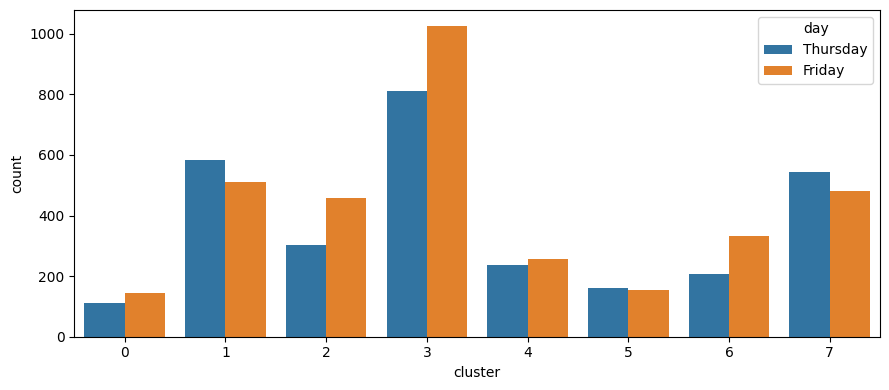

In [7]:
parts=[]
for day in ['Thursday','Friday']:
    scores=pd.read_parquet(REP/f'zero_day_scores_{day}.parquet')
    X=np.load(CACHE/f'X_{day}.npy')
    idx=scores.loc[scores.is_unseen_attack,'window_end_index'].to_numpy(dtype=int)
    if len(idx):
        parts.append((scores.loc[scores.is_unseen_attack].copy(), X[idx]))

if not parts:
    print('No anomalous windows flagged; clustering skipped.')
else:
    meta=pd.concat([p[0] for p in parts], ignore_index=True)
    X_anom=np.vstack([p[1] for p in parts]).astype('float32')
    path=CLUST/'kmeans_unseen_attacks.joblib'
    if path.exists():
        km=joblib.load(path); cid=km.predict(X_anom)
    else:
        k=min(8, max(2, len(X_anom)//50))
        km=MiniBatchKMeans(n_clusters=k, random_state=SEED, batch_size=4096, n_init='auto')
        cid=km.fit_predict(X_anom); joblib.dump(km, path)
    meta['cluster']=cid
    meta.to_parquet(CLUST/'unseen_attack_cluster_assignments.parquet', index=False)
    profile=pd.DataFrame(X_anom, columns=selected).groupby(cid).mean()
    profile.index.name='cluster'
    profile['n_windows']=meta.groupby('cluster').size()
    profile['dominant_label_audit_only']=meta.groupby('cluster').Label.agg(lambda s:s.value_counts().index[0])
    profile['label_mix_audit_only']=meta.groupby('cluster').Label.agg(lambda s:dict(s.value_counts().head(5)))
    profile.to_csv(CLUST/'cluster_feature_profiles.csv')
    display(profile.sort_values('n_windows', ascending=False))
    plt.figure(figsize=(9,4)); sns.countplot(data=meta,x='cluster',hue='day'); plt.tight_layout(); plt.savefig(CLUST/'cluster_sizes.png',dpi=140); plt.show()

## 4 · Engine C: Isolated Per-Day Specialist Classifiers

Each Tuesday-Friday model has its own stratified 70/30 split, train-fold-only feature selector/scaler, Keras checkpoint, final `.keras` model, classification report, confusion matrix, and ROC/PR curves.

Epoch 1/4
519/519 ━━━━━━━━━━━━━━━━━━━━ 0s 333ms/step - accuracy: 0.5697 - loss: 0.7086
Epoch 1: val_loss improved from None to 0.11853, saving model to /content/drive/MyDrive/NIDS_CICIDS2017_Project/production_hybrid_nids/models/specialist_Tuesday/best_specialist.keras

Epoch 1: finished saving model to /content/drive/MyDrive/NIDS_CICIDS2017_Project/production_hybrid_nids/models/specialist_Tuesday/best_specialist.keras
519/519 ━━━━━━━━━━━━━━━━━━━━ 359s 414ms/step - accuracy: 0.7614 - loss: 0.3771 - val_accuracy: 0.9739 - val_loss: 0.1185
Epoch 2/4
519/519 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.9662 - loss: 0.0825
Epoch 2: val_loss improved from 0.11853 to 0.10153, saving model to /content/drive/MyDrive/NIDS_CICIDS2017_Project/production_hybrid_nids/models/specialist_Tuesday/best_specialist.keras

Epoch 2: finished saving model to /content/drive/MyDrive/NIDS_CICIDS2017_Project/production_hybrid_nids/models/specialist_Tuesday/best_specialist.keras
519/519 ━━━━━━━━━━━━━━━━━━━━ 5

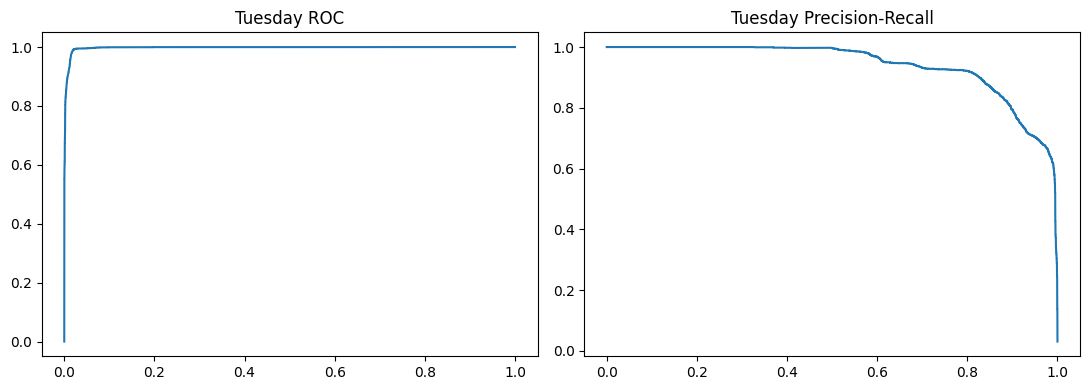

Epoch 1/4
805/805 ━━━━━━━━━━━━━━━━━━━━ 0s 252ms/step - accuracy: 0.7328 - loss: 0.6770
Epoch 1: val_loss improved from None to 0.11308, saving model to /content/drive/MyDrive/NIDS_CICIDS2017_Project/production_hybrid_nids/models/specialist_Wednesday/best_specialist.keras

Epoch 1: finished saving model to /content/drive/MyDrive/NIDS_CICIDS2017_Project/production_hybrid_nids/models/specialist_Wednesday/best_specialist.keras
805/805 ━━━━━━━━━━━━━━━━━━━━ 366s 300ms/step - accuracy: 0.8647 - loss: 0.3394 - val_accuracy: 0.9682 - val_loss: 0.1131
Epoch 2/4
805/805 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - accuracy: 0.9607 - loss: 0.0752
Epoch 2: val_loss improved from 0.11308 to 0.10362, saving model to /content/drive/MyDrive/NIDS_CICIDS2017_Project/production_hybrid_nids/models/specialist_Wednesday/best_specialist.keras

Epoch 2: finished saving model to /content/drive/MyDrive/NIDS_CICIDS2017_Project/production_hybrid_nids/models/specialist_Wednesday/best_specialist.keras
805/805 ━━━━━━━━━━━━━━

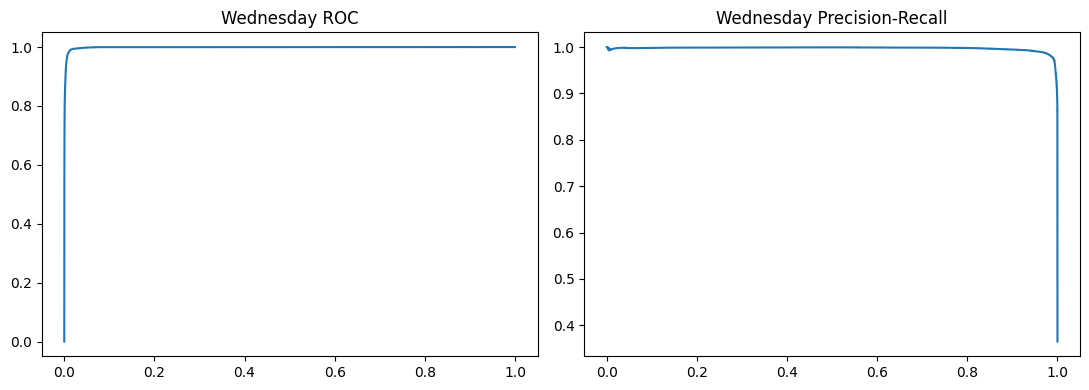

Epoch 1/4


In [ ]:
LOOKBACK_CLS=10; CLS_BATCH=512; CLS_EPOCHS=4 if not SMOKE_TEST else 2; CLS_PATIENCE=5
DAY_TOP_K=32; SPECIALIST_DAYS=['Tuesday','Wednesday','Thursday','Friday']

def stratified_day_split(day):
    df=load_day(day); y=df.Label.to_numpy(); vc=pd.Series(y).value_counts()
    strat=np.array([lbl if vc[lbl]>=2 else ('RARE_ATTACK' if lbl!='BENIGN' else 'BENIGN') for lbl in y])
    return [np.sort(a) for a in next(StratifiedShuffleSplit(n_splits=1,test_size=.3,random_state=SEED).split(np.zeros(len(strat)), strat))]

def fit_day_pipeline(day, train_idx):
    fdir=FEAT/f'specialist_{day}'; fdir.mkdir(parents=True, exist_ok=True)
    df=load_day(day); tr=df.iloc[train_idx].reset_index(drop=True)
    med=tr[raw_features].median(); imp=tr[raw_features].fillna(med)
    const=imp.nunique()[lambda s:s<=1].index.tolist(); rem=[c for c in raw_features if c not in const]
    y=(tr.Label!='BENIGN').astype('int8').to_numpy(); rng=np.random.default_rng(SEED)
    def cap(y,n): return np.sort(np.concatenate([rng.choice(np.where(y==c)[0], min(n,int((y==c).sum())), replace=False) for c in np.unique(y)]))
    X=imp[rem].to_numpy('float32'); irf,imi=cap(y,60_000),cap(y,12_000)
    rf=RandomForestClassifier(n_estimators=160,min_samples_leaf=2,class_weight='balanced_subsample',n_jobs=-1,random_state=SEED).fit(X[irf],y[irf])
    mi=mutual_info_classif(X[imi], y[imi], random_state=SEED)
    rank=pd.DataFrame({'feature':rem,'rf_importance':rf.feature_importances_,'mutual_info':mi})
    rank['combined_rank']=(rank.rf_importance.rank(ascending=False)+rank.mutual_info.rank(ascending=False))/2
    rank=rank.sort_values(['combined_rank','rf_importance'], ascending=[True,False]).reset_index(drop=True)
    feats=rank.feature.head(min(DAY_TOP_K,len(rank))).tolist()
    scaler=StandardScaler().fit(slog(tr[feats].fillna(med[feats]).to_numpy('float32')))
    rank.to_csv(fdir/'feature_ranking.csv', index=False)
    (fdir/'selected_features.json').write_text(json.dumps({'day':day,'k':len(feats),'features':feats,'train_split_only':True}, indent=2))
    joblib.dump({'medians':med[feats],'scaler':scaler,'rf_selector':rf}, fdir/'pipeline.joblib')
    return feats, med[feats], scaler

def transform_day(day, feats, med, scaler):
    df=load_day(day)
    return np.clip(scaler.transform(slog(df[feats].fillna(med).to_numpy('float32'))), -5, 5).astype('float32')

def build_specialist(n_features, lookback, n_classes):
    inp=keras.Input((lookback,n_features), name='window_features')
    ft=build_ft_encoder(n_features,48,4,2,0.1,'cls_ft_encoder')
    z=layers.TimeDistributed(ft, name='encode_each_flow')(inp)
    z=tcn_stack(z,96,3,(1,2,4,8),0.1)
    z=layers.GlobalAveragePooling1D()(z)
    z=layers.Dense(128,activation='gelu')(z); z=layers.Dropout(.2)(z)
    return keras.Model(inp, layers.Dense(n_classes,activation='softmax',name='class_probability')(z), name='ft_transformer_tcn_specialist')

def train_specialist(day):
    mdir=MODELS/f'specialist_{day}'; mdir.mkdir(parents=True, exist_ok=True)
    final=mdir/f'specialist_{day}.keras'; rpath=REP/f'specialist_{day}_metrics.json'
    if final.exists() and rpath.exists():
        print(day, 'already trained.'); return json.loads(rpath.read_text())
    df=load_day(day); tr_idx,te_idx=stratified_day_split(day)
    feats,med,scaler=fit_day_pipeline(day,tr_idx); X=transform_day(day,feats,med,scaler)
    le=LabelEncoder().fit(df.Label.iloc[tr_idx])
    te_idx=te_idx[np.isin(df.Label.iloc[te_idx], le.classes_)]
    y_train = le.transform(df.Label.iloc[tr_idx])
    y_test = le.transform(df.Label.iloc[te_idx])
    Xtr,ytr,_=make_windows(X[tr_idx], y_train, LOOKBACK_CLS)
    Xte,yte,_=make_windows(X[te_idx], y_test, LOOKBACK_CLS)
    if SMOKE_TEST:
        Xtr,ytr,Xte,yte = Xtr[:5000],ytr[:5000],Xte[:5000],yte[:5000]
    classes=np.arange(len(le.classes_))
    cw=compute_class_weight('balanced', classes=classes, y=ytr)
    class_weight={int(c):float(min(w,40.0)) for c,w in zip(classes,cw)}
    model=build_specialist(len(feats), LOOKBACK_CLS, len(le.classes_))
    model.compile(keras.optimizers.AdamW(5e-4,weight_decay=1e-4,clipnorm=1.0), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    cb=[keras.callbacks.ModelCheckpoint(str(mdir/'best_specialist.keras'), monitor='val_loss', mode='min', save_best_only=True, verbose=1),
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=CLS_PATIENCE, restore_best_weights=True)]
    hist=model.fit(Xtr,ytr,validation_split=.15,epochs=CLS_EPOCHS,batch_size=CLS_BATCH,class_weight=class_weight,callbacks=cb,verbose=1)
    probs=model.predict(Xte,batch_size=2048,verbose=0); pred=probs.argmax(1)
    model.save(final); joblib.dump(le,mdir/'label_encoder.joblib'); np.save(mdir/'test_probs.npy',probs); np.save(mdir/'test_true.npy',yte)
    pd.DataFrame(hist.history).to_csv(mdir/'training_history.csv', index=False)
    labels=list(le.classes_)
    print('\n=====', day, 'classification report =====')
    print(classification_report(yte,pred,target_names=labels,zero_division=0))
    pd.DataFrame(confusion_matrix(yte,pred,labels=classes), index=labels, columns=labels).to_csv(REP/f'specialist_{day}_confusion_matrix.csv')
    benign_idx=labels.index('BENIGN') if 'BENIGN' in labels else None
    attack_score=1-probs[:,benign_idx] if benign_idx is not None else probs.max(1)
    ybin=(np.array(labels)[yte] != 'BENIGN').astype(int)
    ap=float(average_precision_score(ybin,attack_score)) if len(np.unique(ybin))==2 else np.nan
    auc=float(roc_auc_score(ybin,attack_score)) if len(np.unique(ybin))==2 else np.nan
    try:
        macro_auc=float(roc_auc_score(label_binarize(yte,classes=classes), probs, average='macro', multi_class='ovr'))
    except Exception:
        macro_auc=np.nan
    metrics={'day':day,'classes':labels,'n_train_windows':int(len(Xtr)),'n_test_windows':int(len(Xte)),'classification_report':classification_report(yte,pred,target_names=labels,zero_division=0,output_dict=True),'attack_vs_benign_average_precision':ap,'attack_vs_benign_roc_auc':auc,'macro_multiclass_roc_auc_ovr':macro_auc,'split':'StratifiedShuffleSplit 70/30'}
    rpath.write_text(json.dumps(metrics, indent=2))
    fpr,tpr,_=roc_curve(ybin,attack_score) if len(np.unique(ybin))==2 else ([0,1],[0,1],None)
    pr,rc,_=precision_recall_curve(ybin,attack_score) if len(np.unique(ybin))==2 else ([1,0],[0,1],None)
    fig,ax=plt.subplots(1,2,figsize=(11,4)); ax[0].plot(fpr,tpr); ax[0].set_title(f'{day} ROC'); ax[1].plot(rc,pr); ax[1].set_title(f'{day} Precision-Recall'); plt.tight_layout(); plt.savefig(REP/f'specialist_{day}_roc_pr.png',dpi=140); plt.show()
    return metrics

results=[train_specialist(d) for d in SPECIALIST_DAYS]
summary=pd.DataFrame([{'day':r['day'],'classes':len(r['classes']),'train_windows':r['n_train_windows'],'test_windows':r['n_test_windows'],'AP':r['attack_vs_benign_average_precision'],'ROC_AUC':r['attack_vs_benign_roc_auc'],'macro_multiclass_ROC_AUC_OVR':r['macro_multiclass_roc_auc_ovr']} for r in results])
summary.to_csv(REP/'specialist_summary.csv', index=False)
display(summary.round(4))

## 5 · Persistence and Run Order

Run order from this folder:

1. Run `07_production_hybrid_nids.ipynb` top-to-bottom in Colab with a GPU.
2. Keep `SMOKE_TEST = False` for the real run; set it to `True` only for a fast wiring check.
3. Re-running is safe: cached parquet, `.npy`, `.joblib`, checkpoint, and `.keras` artifacts are reused.

Key outputs:

- Cleaned caches: `production_hybrid_nids/cache/<Day>.parquet`
- Selected feature masks/scalers: `production_hybrid_nids/features/`
- Zero-day AE: `production_hybrid_nids/models/zero_day_autoencoder/`
- Clustering profiles: `production_hybrid_nids/clusters/`
- Per-day specialist models/reports: `production_hybrid_nids/models/specialist_<Day>/` and `production_hybrid_nids/reports/`